# Sparse Identification of Nonlinear Socio-Technical Dynamics (SocioSINDy)

### Load libaries

In [79]:
import pysindy as ps
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import statistics

In [4]:
# ignore user warnings
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

### Set initial conditions of dataset

In [5]:
dt = 1 # timestep size
sample_length = 9 # length of one simulation

n_ics = 27 # number of individual simulations
x_train = [np.zeros((sample_length, 6)) for i in range(n_ics)] # create list of empty arrays

### Load dataset

In [6]:
data = pd.read_csv("safety_barriers.csv", delimiter=";", decimal=",") # load dataset from csv file
data = data.drop(columns=['t']) # drop "t" column
data.head()

,Communication reliability (Dmnl),Stable zero enforcement time (seconds),Stable zero enforcement effectivess (Dmnl),"Residual gas discovery, pending vent",Probability of error generation,Residual gas in hydrogen tank
0,0.9,5,0.9,0.000000,0.293718,0.356115
1,0.9,5,0.9,0.000000,0.389030,0.460712
2,0.9,5,0.9,0.000000,0.463863,0.599252
3,0.9,5,0.9,0.624150,0.807010,0.764441
4,0.9,5,0.9,0.234647,0.536306,0.287388


In [7]:
data_np = data.to_numpy(dtype="float") # convert dataframe to numpy array

In [8]:
# fill empty list of arrays with values from loaded dataset
for idx in range(n_ics):
    x_train[idx][:] = data_np[(idx*sample_length):((idx*sample_length)+sample_length), :]

In [9]:
# scale the second column (index 1) from 0 to 1
for idx in range(n_ics):
    x_train[idx][:, 1] = (x_train[idx][:, 1] - 0) / (5 - 0)

### Split dataset into control features and input features

In [10]:
u_train = [x_train[i][:, :3] for i in range(n_ics)] # control features
x_train = [x_train[i][:, 3:] for i in range(n_ics)] # input features

## Fit model to data (coefficient approach)

### Split x_train and u_train into train and test dataset

In [66]:
x_train_split, x_test_split, u_train_split, u_test_split = train_test_split(x_train, u_train, test_size=0.3, random_state=42)

print(f"Training set size: {len(x_train_split)}")
print(f"Test set size: {len(x_test_split)}")

Training set size: 18
Test set size: 9


### Initiate and fit model

In [94]:
threshold = 0.5
degree=2

optimizer = ps.STLSQ(threshold=threshold, normalize_columns=True)
library = ps.PolynomialLibrary(degree=degree, interaction_only=False)
coeff_model = ps.DiscreteSINDy(optimizer=optimizer, feature_library=library)
coeff_model.fit(x=x_train_split, t=dt, u=u_train_split)
coeff_model.print()

(x0)[k+1] = -0.665 1 +  0.697 x1[k] + -0.091 x0[k]^2 + -1.656 x0[k] x2[k] + -1.897 x1[k] x2[k] +  0.613 x1[k] u0[k] +  0.326 x1[k] u1[k] +  0.284 x1[k] u2[k] +  2.520 x2[k]^2
(x1)[k+1] =  0.182 1 +  1.700 x1[k] + -0.654 x2[k] + -2.656 x0[k]^2 +  13.382 x0[k] x1[k] + -10.489 x0[k] x2[k] +  0.684 x1[k]^2 + -11.552 x1[k] x2[k] + -0.349 x1[k] u0[k] + -0.444 x1[k] u1[k] + -0.427 x1[k] u2[k] +  10.775 x2[k]^2
(x2)[k+1] =  0.153 1 + -0.387 x0[k] +  0.919 x2[k] + -0.760 x0[k] u0[k] +  0.045 x0[k] u2[k] +  0.046 x2[k] u1[k] +  0.026 x2[k] u2[k]


### Asses model on test set

In [95]:
coeff_r2_score = coeff_model.score(x=x_test_split, t=dt, u=u_test_split)
print(f"R^2 score: {coeff_r2_score:.3f}")
coeff_mse_score = coeff_model.score(x=x_test_split, t=dt, u=u_test_split, metric=mean_squared_error)
print(f"MSE score: {coeff_mse_score:.3f}")

R^2 score: 0.910
MSE score: 0.003


## Fit model to data (prediction approach)

### Create bootstrap function

In [11]:
def create_bootstrap_subsets(input_features, control_features, n_subsets=20, test_size=0.2, random_seed=42):
    """
    create multiple bootstrap subsets (sampling with replacement)
    """
    np.random.seed(random_seed)
    subsets = []
    n_total = len(input_features)
    n_test = int(test_size * n_total)  # Size of OOB (out-of-bag) sample
    
    for subset_num in range(n_subsets):
        # bootstrap sample: sample WITH replacement for training
        train_idx = np.random.choice(n_total, size=n_total, replace=True)
        
        # Out-of-bag (OOB) sample: indices not in bootstrap sample for testing
        all_indices = set(range(n_total))
        bootstrap_indices = set(train_idx)
        test_idx = np.array(list(all_indices - bootstrap_indices))
        
        if len(test_idx) < n_test: # if OOB sample is too small, randomly select test samples
            # get additional random indices for testing
            remaining = np.array(list(all_indices - set(test_idx)))
            additional = np.random.choice(remaining, size=n_test-len(test_idx), replace=False)
            test_idx = np.concatenate([test_idx, additional])
        
        train_data = [input_features[i] for i in train_idx]
        u_train_data = [control_features[i] for i in train_idx]
        
        # for test data, use the original order (without replacement)
        test_data = [input_features[i] for i in test_idx] if len(test_idx) > 0 else []
        u_test_data = [control_features[i] for i in test_idx] if len(test_idx) > 0 else []
        
        subsets.append({
            'subset_num': subset_num,
            'train_indices': train_idx,  # NOTE: has duplicates due to replacement
            'test_indices': test_idx,    # OOB sample
            'train_data': train_data,
            'test_data': test_data,
            'u_train_data': u_train_data,
            'u_test_data': u_test_data,
            'bootstrap_duplicates': len(train_idx) - len(set(train_idx))  # ccount of duplicates
        })
        
        print(f"\nBootstrap subset {subset_num + 1}:")
        print(f"  Train subsets: {len(train_idx)} (with replacement)")
        print(f"  Unique train subsets: {len(set(train_idx))}")
        print(f"  Test subsets (OOB): {len(test_idx)}")
    
    return subsets

### Generate bootstrap subsets

In [12]:
n_subsets = 200 # number of subsets
test_size = 0.2 # percentage of test size

subsets = create_bootstrap_subsets(input_features=x_train, control_features=u_train, n_subsets=200, test_size=test_size) # call function


Bootstrap subset 1:
  Train subsets: 27 (with replacement)
  Unique train subsets: 17
  Test subsets (OOB): 10

Bootstrap subset 2:
  Train subsets: 27 (with replacement)
  Unique train subsets: 19
  Test subsets (OOB): 8

Bootstrap subset 3:
  Train subsets: 27 (with replacement)
  Unique train subsets: 17
  Test subsets (OOB): 10

Bootstrap subset 4:
  Train subsets: 27 (with replacement)
  Unique train subsets: 17
  Test subsets (OOB): 10

Bootstrap subset 5:
  Train subsets: 27 (with replacement)
  Unique train subsets: 16
  Test subsets (OOB): 11

Bootstrap subset 6:
  Train subsets: 27 (with replacement)
  Unique train subsets: 15
  Test subsets (OOB): 12

Bootstrap subset 7:
  Train subsets: 27 (with replacement)
  Unique train subsets: 19
  Test subsets (OOB): 8

Bootstrap subset 8:
  Train subsets: 27 (with replacement)
  Unique train subsets: 18
  Test subsets (OOB): 9

Bootstrap subset 9:
  Train subsets: 27 (with replacement)
  Unique train subsets: 15
  Test subsets (OOB)

### Create confidence interval function

In [13]:
def calculate_confidence(scores, confidence=0.95):
    """
    calculate confidence interval from bootstrap scores
    """
    alpha = 1 - confidence
    lower_percentile = (alpha / 2) * 100
    upper_percentile = (1 - alpha / 2) * 100
    
    ci_lower = np.percentile(scores, lower_percentile)
    ci_upper = np.percentile(scores, upper_percentile)
    
    return ci_lower, ci_upper

### Initiate DiscreteSINDy model

In [ ]:
threshold = 0.4
degree=2

optimizer = ps.STLSQ(threshold=threshold, normalize_columns=True)
library = ps.PolynomialLibrary(degree=degree, interaction_only=False)
pred_model = ps.DiscreteSINDy(optimizer=optimizer, feature_library=library)

### Fit and evaluate model

In [98]:
pred_r2_score = []
pred_mse_score = []
for subset in range(len(subsets)):
    pred_model.fit(subsets[subset]["train_data"], t=dt, u=subsets[subset]["u_train_data"])
    if subset % 50 == 0:
        pred_model.print()
        print("\n")
    pred_r2_score.append(pred_model.score(subsets[subset]["test_data"], t=dt, u=subsets[subset]["u_test_data"]))
    pred_mse_score.append(pred_model.score(subsets[subset]["test_data"], t=dt, u=subsets[subset]["u_test_data"], metric=mean_squared_error))
    #print(model.score(splits[split]["test_data"], t=dt, u=splits[split]["u_test_data"], metric=mean_squared_error))
    
ci_lower_r2, ci_upper_r2 = calculate_confidence(pred_r2_score, confidence=0.95) # confidence interval for r2 score
print(f"Mean R^2 score: {(sum(pred_r2_score)/len(subsets)):.3f}")
print(f"95% Confidence Interval for R^2 score: [{ci_lower_r2:.3f}, {ci_upper_r2:.3f}]")

ci_lower_mse, ci_upper_mse = calculate_confidence(pred_mse_score, confidence=0.95) # confidence interval for MSE score
print(f"Mean MSE score: {(sum(pred_mse_score)/len(subsets)):.3f}")
print(f"95% Confidence Interval for MSE score: [{ci_lower_mse:.4f}, {ci_upper_mse:.4f}]")

(x0)[k+1] = -1.801 1 +  5.029 x1[k] +  0.310 u0[k] +  0.688 u1[k] +  0.714 u2[k] + -5.026 x0[k]^2 +  28.850 x0[k] x1[k] + -19.899 x0[k] x2[k] + -0.709 x1[k]^2 + -22.422 x1[k] x2[k] + -0.518 x1[k] u0[k] + -2.118 x1[k] u1[k] + -1.882 x1[k] u2[k] +  18.305 x2[k]^2 +  0.348 x2[k] u1[k]
(x1)[k+1] =  0.077 1 +  3.276 x1[k] + -1.392 x2[k] + -5.007 x0[k]^2 +  17.197 x0[k] x1[k] + -11.336 x0[k] x2[k] + -0.321 x1[k]^2 + -13.456 x1[k] x2[k] + -0.668 x1[k] u0[k] + -0.971 x1[k] u1[k] + -0.858 x1[k] u2[k] +  12.118 x2[k]^2 +  0.636 x2[k] u1[k] +  0.522 x2[k] u2[k]
(x2)[k+1] = -0.022 1 +  0.469 x0[k] +  0.319 x1[k] +  1.144 x2[k] +  0.326 x0[k]^2 + -1.128 x0[k] x1[k] +  0.258 x0[k] x2[k] + -1.197 x0[k] u0[k] +  0.004 x0[k] u2[k] + -0.277 x1[k] x2[k] +  0.076 x2[k]^2 +  0.002 x2[k] u0[k] +  0.003 x2[k] u1[k] +  0.001 x2[k] u2[k]


(x0)[k+1] = -0.373 1 +  0.231 x1[k] + -0.255 u0[k] +  0.574 u2[k] + -5.327 x0[k]^2 +  22.803 x0[k] x1[k] + -15.486 x0[k] x2[k] + -0.383 x0[k] u1[k] +  1.310 x1[k]^2 + -18.73

### Plot the histogram and confidence interval for MSE score

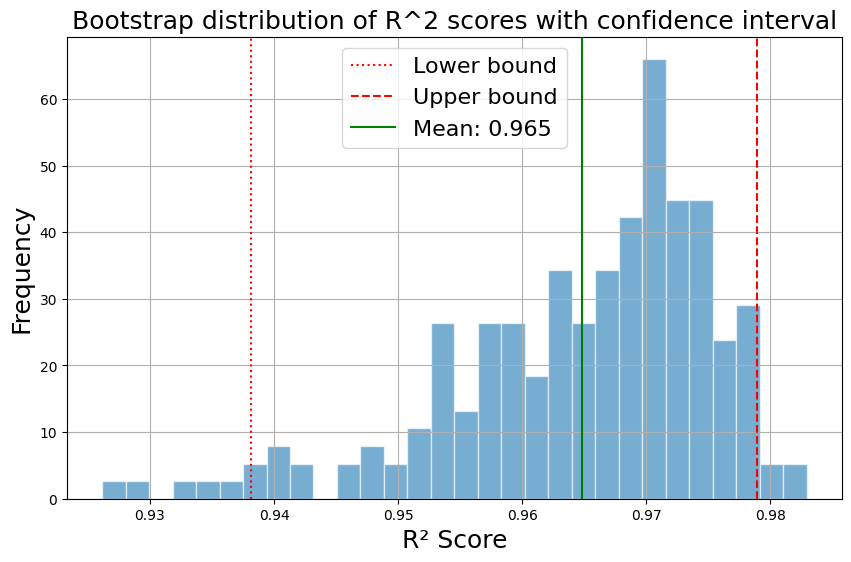

In [101]:
plt.figure(figsize=(10, 6))

# histogram of bootstrap scores
plt.hist(pred_r2_score, bins=30, edgecolor="white", alpha=0.6, density=True)

# Add confidence interval lines
plt.axvline(ci_lower_r2, color='red', linestyle='dotted', label=f'Lower bound')
plt.axvline(ci_upper_r2, color='red', linestyle='dashed', label=f'Upper bound')
plt.axvline(statistics.mean(pred_r2_score), color='green', label=f'Mean: {statistics.mean(pred_r2_score):.3f}')

plt.xlabel('R² Score', fontsize=18)
plt.ylabel('Frequency', fontsize=18)
plt.title('Bootstrap distribution of R^2 scores with confidence interval', fontsize=18)
plt.grid()
plt.legend(fontsize=16)
plt.show()